# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)

torch.manual_seed(42)

## Step 2 — Load the supplied dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x.ne(0)
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x).masked_fill(~mask.unsqueeze(-1), float("-inf")), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

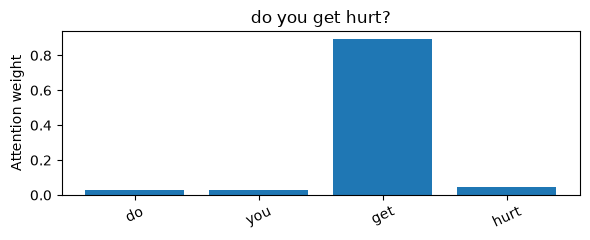

Highest: get (0.893)


In [6]:
def plot_attention(row):
    model.eval()
    with torch.no_grad():
        _, weights = model(X[row:row + 1])
    mask = X[row] != 0
    words = [tokenizer.index_word[i] for i in X[row, mask].tolist()]
    values = weights[0, mask]
    assert torch.isclose(values.sum(), torch.tensor(1.0)) and (weights[0, ~mask] == 0).all()
    positions = range(len(words))
    fig, ax = plt.subplots(figsize=(6, 2.5))
    ax.bar(positions, values.tolist())
    ax.set_xticks(list(positions), words, rotation=25)
    ax.set_ylabel("Attention weight")
    ax.set_title(df.loc[row, "question"])
    fig.tight_layout()
    plt.show()
    best = values.argmax().item()
    print(f"Highest: {words[best]} ({values[best]:.3f})")
    return words[best]

_ = plot_attention(0)

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

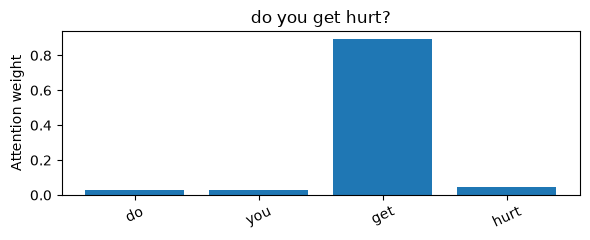

Highest: get (0.893)


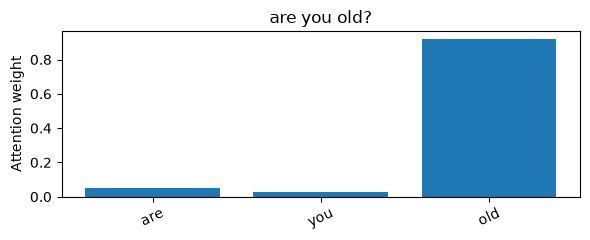

Highest: old (0.919)


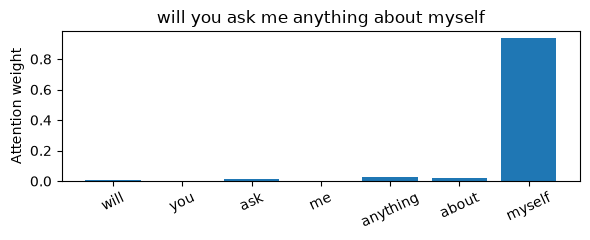

Highest: myself (0.935)


In [7]:
rows = df.groupby("answer_id", sort=True).head(1).index[:3]
for row in rows:
    plot_attention(row)

The highest weights fell on **get** (0.893), **old** (0.919), and **myself** (0.935). “Old” directly signals age, and “myself” identifies whom the question is about. In “Do you get hurt?”, a person might choose “hurt” as the clearest clue. The RNN instead puts most of its weight on the state at “get”. A weight describes how the classifier combines contextual states, so it does not establish which single word determines the meaning.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

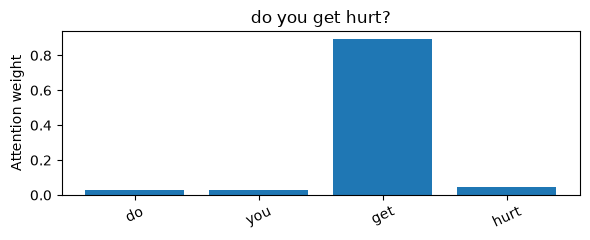

Highest: get (0.893)


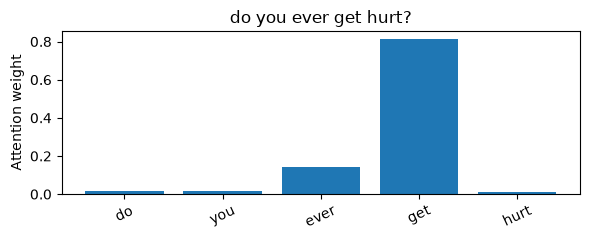

Highest: get (0.813)


In [8]:
variants = ["do you get hurt?", "do you ever get hurt?"]
for question in variants:
    row = df.index[df["question"] == question][0]
    plot_attention(row)

Both questions peak at **get**. Its weight falls from **0.893** in “Do you get hurt?” to **0.813** in “Do you ever get hurt?”. Adding “ever” changes the context and redistributes some attention, even though the questions still ask about the same experience.